# Laboratorium: Adaline i spadek gradientu

**Podstawy AI**

Na poprzednich zajęciach perceptron uczył się na pomyłkach: błąd $y - \hat y$ miał tylko wartości $0, \pm 1$. Dziś zbudujesz **Adaline** (Widrow i Hoff, 1960): neuron, który wie, *jak bardzo* się myli, i uczy się, minimalizując **funkcję straty** metodą **spadku gradientu**.

Plan:
1. spadek gradientu na jednej wadze (kartka 1 w kodzie),
2. implementacja Adaline,
3. Adaline na danych Iris: za duże i za małe $\eta$, granica stabilności,
4. mapa $\eta$ × epoki: kiedy więcej epok pomaga,
5. granica decyzyjna w czasie: co się dzieje, gdy trafność jest już 100%.

Dziś skupiamy się na zrozumieniu, jak $\eta$ i liczba epok wpływają na uczenie. Standaryzację i stochastyczny spadek gradientu poznamy na następnych zajęciach.

**Jak pracujemy:** komórki oznaczone `# TODO` uzupełniasz sam. W eksperymentach stosujemy zasadę **przewiduję → uruchamiam → wyjaśniam**.

**Na koniec:** wrzuć uzupełniony notebook na swojego GitHuba.

Notebook wzoruje się na rozdziale 2 książki S. Raschki *Machine Learning with PyTorch and Scikit-Learn*.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.datasets import load_iris

np.set_printoptions(precision=4, suppress=True)

## 1. Spadek gradientu na jednej wadze

Na kartce 1 liczyłeś ręcznie kroki spadku gradientu dla

$$L(w) = (w - 3)^2, \qquad w_{k+1} = w_k - \eta \cdot 2(w_k - 3), \qquad w_0 = 0.$$

Teraz to samo w kodzie, dla wielu kroków i wielu wartości $\eta$.

### Zadanie 1
Uzupełnij funkcję `spadek_1d`: w pętli policz kolejne $w_{k+1}$ z $w_k$ i dopisz do listy. Funkcja zwraca listę $[w_0, w_1, \dots, w_n]$.

In [ ]:
def spadek_1d(eta, w0=0.0, n_krokow=10):
    w = w0
    trajektoria = [w]
    for k in range(n_krokow):
        w = w - eta * 2 * (w - 3)
        trajektoria.append(w)
    return trajektoria

In [ ]:
# Sprawdzenie z kartką 1: pierwsze trzy kroki
for eta in [0.25, 1.0, 1.1]:
    print(f"η = {eta:<5}", [round(w, 4) for w in spadek_1d(eta, n_krokow=3)])

η = 0.25  [0.0, 1.5, 2.25, 2.625]
η = 1.0   [0.0, 6.0, 0.0, 6.0]
η = 1.1   [0.0, 6.6, -1.32, 8.184]


Powinieneś zobaczyć dokładnie to, co na kartce: $[0, 1.5, 2.25, 2.625]$, $[0, 6, 0, 6]$ i $[0, 6.6, -1.32, 8.184]$.

Teraz narysujmy trajektorie dla większej liczby $\eta$, po 10 kroków.

**Przewiduję:** przy którym $\eta$ z listy $\{0.1,\ 0.25,\ 0.5,\ 0.9,\ 1.0,\ 1.1\}$ dojdziemy do minimum najszybciej?

✍️ **Moje przewidywanie (zapisz przed uruchomieniem):** Najszybciej dojdziemy do minimum przy η = 0.5, bo wtedy chyba trafiamy w w = 3 już w jednym kroku.

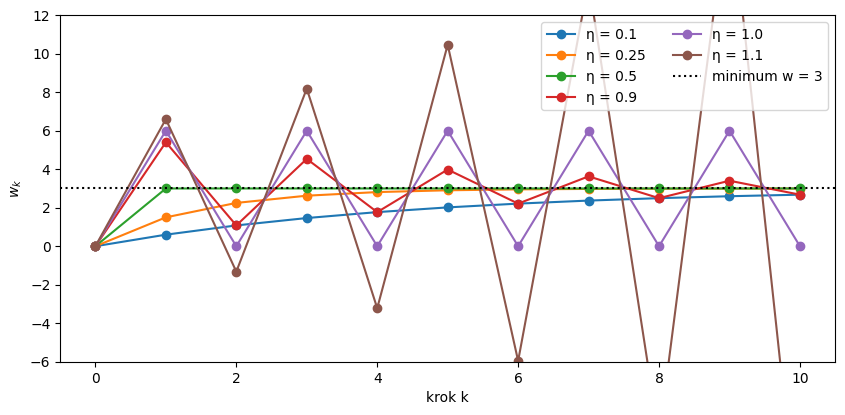

η = 0.1   w_10 =     2.6779
η = 0.25  w_10 =     2.9971
η = 0.5   w_10 =     3.0000
η = 0.9   w_10 =     2.6779
η = 1.0   w_10 =     0.0000
η = 1.1   w_10 =   -15.5752


In [ ]:
fig, ax = plt.subplots(figsize=(10, 4.5))
for eta in [0.1, 0.25, 0.5, 0.9, 1.0, 1.1]:
    ax.plot(range(11), spadek_1d(eta), marker="o", label=f"η = {eta}")
ax.axhline(3, color="k", ls=":", label="minimum w = 3")
ax.set_xlabel("krok k"); ax.set_ylabel("$w_k$"); ax.set_ylim(-6, 12)
ax.legend(ncol=2); plt.show()

for eta in [0.1, 0.25, 0.5, 0.9, 1.0, 1.1]:
    print(f"η = {eta:<4}  w_10 = {spadek_1d(eta)[-1]:10.4f}")

**Pytanie 1.** (a) Przy którym $\eta$ dochodzimy do minimum w **jednym** kroku? (b) Dlaczego przy $\eta = 0.9$ waga skacze na boki, a mimo to zbiega? (c) Gdzie jest granica między zbieżnością a rozbieżnością?

Wskazówka: przekształć wzór na krok do postaci $w_{k+1} - 3 = c \cdot (w_k - 3)$. Ile wynosi $c$?

✍️ **Twoja odpowiedź:** (a) Przy η = 0.5: w₁ = 0 − 0.5·2·(0 − 3) = 3, czyli od razu minimum.

(b) Wzór na krok: w_{k+1} − 3 = (1 − 2η)(w_k − 3), czyli c = 1 − 2η. Dla η = 0.9 mamy c = −0.8: znak odległości od minimum zmienia się w każdym kroku (waga przeskakuje na drugą stronę w = 3, stąd skakanie na boki), ale |c| = 0.8 < 1, więc odległość od minimum maleje 0.8 razy w każdym kroku i waga zbiega (w₁₀ ≈ 2.68, tak samo jak dla η = 0.1, gdzie c = 0.8, tylko bez skakania).

(c) Zbieżność jest, gdy |c| < 1, czyli |1 − 2η| < 1, czyli 0 < η < 1. Dla η = 1 mamy c = −1 (waga skacze 0, 6, 0, 6 i nigdy nie dochodzi do minimum), a dla η = 1.1 mamy c = −1.2, |c| > 1 i odległość od minimum rośnie (0, 6.6, −1.32, 8.18, ..., w₁₀ ≈ −15.6), czyli rozbieżność.

## 2. Adaline — przypomnienie

Neuron liczy, tak jak perceptron, **pobudzenie** $z = \mathbf{w}^T\mathbf{x} + b$. Różnica jest w uczeniu:

| | perceptron | Adaline |
|---|---|---|
| błąd | $y - \hat{y}$, tylko $0, \pm 1$ | $y - z$, dowolna liczba |
| poprawka | po każdym przykładzie | raz na epokę, z całego zbioru |
| predykcja | $\hat y = 1$, gdy $z \ge 0$ | $\hat y = 1$, gdy $z \ge 0.5$ |

**Funkcja straty** (średni błąd kwadratowy, MSE) mówi jedną liczbą, jak źle jest:

$$L(\mathbf{w}, b) = \frac{1}{n}\sum_{i=1}^{n}\left(y^{(i)} - z^{(i)}\right)^2$$

**Spadek gradientu.** Pochodne straty po wagach i biasie (wyprowadzenie na slajdach):

$$\frac{\partial L}{\partial w_j} = -\frac{2}{n}\sum_i \left(y^{(i)} - z^{(i)}\right) x_j^{(i)}, \qquad \frac{\partial L}{\partial b} = -\frac{2}{n}\sum_i \left(y^{(i)} - z^{(i)}\right)$$

Robimy krok w stronę przeciwną do gradientu:

$$w_j := w_j + \eta \cdot \frac{2}{n}\sum_i \left(y^{(i)} - z^{(i)}\right) x_j^{(i)}, \qquad b := b + \eta \cdot \frac{2}{n}\sum_i \left(y^{(i)} - z^{(i)}\right)$$

### Zadanie 2 — uzupełnij metodę `fit`

Brakuje **czterech linijek** w pętli uczącej:
1. `errors` — wektor błędów $y - z$ dla **wszystkich** przykładów naraz (`output` jest już policzone),
2. aktualizacja wag `self.w_`,
3. aktualizacja biasu `self.b_`,
4. `loss` — średni błąd kwadratowy w tej epoce.

Wskazówki:
- sumę $\sum_i e^{(i)} x_j^{(i)}$ dla wszystkich $j$ naraz liczy `X.T @ errors`,
- $n$ to `X.shape[0]`,
- średnią liczy `.mean()`, kwadrat `** 2`.

Parametr `verbose=True` wypisuje stan po każdej epoce, tak jak liczyłeś na kartce.

In [ ]:
class AdalineGD:
    """ADAptive LInear NEuron, uczony pełnym spadkiem gradientu (etykiety 0/1).

    Parametry
    ---------
    eta : float        współczynnik uczenia
    n_iter : int       liczba epok
    w_init : str       'random' (małe losowe, jak u Raschki) albo 'zeros'
    random_state : int ziarno generatora liczb losowych
    verbose : bool     czy wypisywać stan po każdej epoce

    Atrybuty po uczeniu
    -------------------
    w_ : wagi,  b_ : bias,  losses_ : wartość MSE w każdej epoce
    """

    def __init__(self, eta=0.01, n_iter=50, w_init="random", random_state=1, verbose=False):
        self.eta = eta
        self.n_iter = n_iter
        self.w_init = w_init
        self.random_state = random_state
        self.verbose = verbose

    def fit(self, X, y):
        if self.w_init == "zeros":
            self.w_ = np.zeros(X.shape[1])
        else:
            rgen = np.random.RandomState(self.random_state)
            self.w_ = rgen.normal(loc=0.0, scale=0.01, size=X.shape[1])
        self.b_ = 0.0
        self.losses_ = []

        for epoka in range(1, self.n_iter + 1):
            net_input = self.net_input(X)          # z dla WSZYSTKICH przykładów naraz
            output = self.activation(net_input)    # Adaline: aktywacja liniowa, output = z
            errors = y - output
            self.w_ += self.eta * 2.0 * X.T @ errors / X.shape[0]
            self.b_ += self.eta * 2.0 * errors.mean()
            loss = (errors ** 2).mean()
            self.losses_.append(loss)
            if self.verbose:
                print(f"epoka {epoka}: z = {output}, błędy = {errors}, "
                      f"MSE = {loss:.4f} -> nowe w = {self.w_}, b = {self.b_:.4f}")
        return self

    def net_input(self, X):
        """Pobudzenie z = w^T x + b"""
        return np.dot(X, self.w_) + self.b_

    def activation(self, X):
        """Liniowa funkcja aktywacji: sigma(z) = z"""
        return X

    def predict(self, X):
        """Klasa po progu 0.5"""
        return np.where(self.activation(self.net_input(X)) >= 0.5, 1, 0)

## 3. Sprawdzenie na przykładzie z kartki 2

Punkty A–D z poprzednich zajęć, start od zerowych wag, $\eta = 0.05$, dwie epoki. Na kartce 2 liczyłeś:
- epoka 1: $z = 0$ dla wszystkich, błędy $(1, 0, 1, 0)$, MSE $= 0.5$, nowe wagi $w = (0.125,\ 0.075)$, $b = 0.05$,
- epoka 2: $z = (0.375,\ 0.4,\ 0.575,\ 0.2)$, MSE $\approx 0.193$.

In [ ]:
X_kartka = np.array([[2, 1], [1, 3], [3, 2], [0, 2]], dtype=float)
y_kartka = np.array([1, 0, 1, 0])

ada_k = AdalineGD(eta=0.05, n_iter=2, w_init="zeros", verbose=True).fit(X_kartka, y_kartka)

epoka 1: z = [0. 0. 0. 0.], błędy = [1. 0. 1. 0.], MSE = 0.5000 -> nowe w = [0.125 0.075], b = 0.0500
epoka 2: z = [0.375 0.4   0.575 0.2  ], błędy = [ 0.625 -0.4    0.425 -0.2  ], MSE = 0.1928 -> nowe w = [0.1781 0.0719], b = 0.0612


In [ ]:
# Test: jeśli ta komórka nie zgłasza błędu, Twoja implementacja jest poprawna
ada_1 = AdalineGD(eta=0.05, n_iter=1, w_init="zeros").fit(X_kartka, y_kartka)
assert np.allclose(ada_1.w_, [0.125, 0.075]) and np.isclose(ada_1.b_, 0.05), f"Po 1. epoce: w={ada_1.w_}, b={ada_1.b_}"
assert np.allclose(ada_k.losses_, [0.5, 0.1928125]), f"Straty: {ada_k.losses_}"
print("✅ Wynik zgodny z kartką")
print("predykcje po 1. epoce:", ada_1.predict(X_kartka), " prawdziwe:", y_kartka)

✅ Wynik zgodny z kartką
predykcje po 1. epoce: [0 0 1 0]  prawdziwe: [1 0 1 0]


**Pytanie 2.** Po pierwszej epoce punkt B jest klasyfikowany poprawnie ($z = 0.4 < 0.5$), a mimo to w drugiej epoce wnosi do poprawki błąd $-0.4$. Perceptron w takiej sytuacji nie zmieniłby wag z powodu B. Dlaczego Adaline to robi i co na tym zyskuje?

✍️ **Twoja odpowiedź:** W Adaline błąd to y − z, czyli różnica między prawdziwą etykietą a samym pobudzeniem (przed progiem), więc dla B jest to 0 − 0.4 = −0.4 i nie jest zerem, nawet gdy klasa jest przewidziana dobrze. Adaline nie chce tylko, żeby z było po dobrej stronie progu, ale żeby z było jak najbliżej etykiety (0 albo 1), bo minimalizuje MSE. Perceptron patrzy tylko na to, czy się pomylił. Adaline zyskuje to, że ma gładką funkcję straty i wie, jak bardzo się myli i w którą stronę poprawić wagi. Poprawki są proporcjonalne do błędu (większy błąd, większa poprawka), a poprawne punkty też trochę ustawiają granicę, więc uczenie jest płynne i zbiega do minimum zamiast się zatrzymywać w przypadkowym miejscu.

**Pytanie 3.** Raschka pokazuje też wersję aktualizacji wag z pętlą po wagach:
```python
for j in range(self.w_.shape[0]):
    self.w_[j] += self.eta * (2.0 * (X[:, j] * errors)).mean()
```
Dlaczego to daje ten sam wynik co `self.eta * 2.0 * X.T @ errors / X.shape[0]`? Co oblicza wiersz `j` macierzy `X.T` pomnożony przez `errors`?

✍️ **Twoja odpowiedź:** Wiersz j macierzy X.T to kolumna j macierzy X, czyli cecha x_j wszystkich przykładów. Mnożenie przez errors daje iloczyn skalarny, czyli sumę Σᵢ x_j⁽ⁱ⁾ · e⁽ⁱ⁾, a to dokładnie suma z wzoru na pochodną po w_j. Pętla robi to samo osobno dla każdego j: (2.0 · (X[:, j] · errors)).mean() to (2/n) Σᵢ x_j⁽ⁱ⁾ e⁽ⁱ⁾, czyli 2·(X.T @ errors)[j]/n. Wersja macierzowa liczy wszystkie wagi naraz jednym mnożeniem, więc wynik jest ten sam, a kod krótszy i szybszy.

## 4. Iris: za duże i za małe $\eta$

Te same dane co tydzień temu: setosa (0) i versicolor (1), długość działki i długość płatka, w centymetrach.

In [ ]:
iris = load_iris()
X = iris.data[:100][:, [0, 2]]               # cechy: działka, płatek [cm]
y = (iris.target[:100] == 1).astype(int)      # setosa -> 0, versicolor -> 1
print("Kształt X:", X.shape, " Liczba przykładów w klasach:", np.bincount(y))

Kształt X: (100, 2)  Liczba przykładów w klasach: [50 50]


In [ ]:
def plot_decision_regions(X, y, model, resolution=0.02, ax=None, title=None, etykiety=("setosa", "versicolor")):
    ax = ax or plt.gca()
    cmap = ListedColormap(["tab:red", "tab:blue"])
    x1_min, x1_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    x2_min, x2_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx1, xx2 = np.meshgrid(np.arange(x1_min, x1_max, resolution),
                           np.arange(x2_min, x2_max, resolution))
    Z = model.predict(np.array([xx1.ravel(), xx2.ravel()]).T).reshape(xx1.shape)
    ax.contourf(xx1, xx2, Z, alpha=0.25, cmap=cmap)
    for klasa, kolor, marker in [(0, "tab:red", "o"), (1, "tab:blue", "s")]:
        ax.scatter(X[y == klasa, 0], X[y == klasa, 1], c=kolor, marker=marker,
                   edgecolor="black", label=etykiety[klasa])
    ax.set_xlim(x1_min, x1_max); ax.set_ylim(x2_min, x2_max)
    if title: ax.set_title(title)
    ax.legend(loc="upper left")

### Eksperyment A: $\eta = 0.1$ i $\eta = 0.0001$

Uczymy Adaline przez 15 epok z dwoma współczynnikami uczenia.

**Przewiduję:** jak będzie wyglądał wykres straty w obu przypadkach? (Przypomnij sobie kartkę 1.)

✍️ **Moje przewidywanie (zapisz przed uruchomieniem):** Przy η = 0.1 strata raczej będzie rosnąć (rozbieżność, tak jak η > 1 na kartce 1, bo cechy mają duże wartości, więc krok może być za duży). Przy η = 0.0001 strata będzie maleć, ale bardzo powoli.

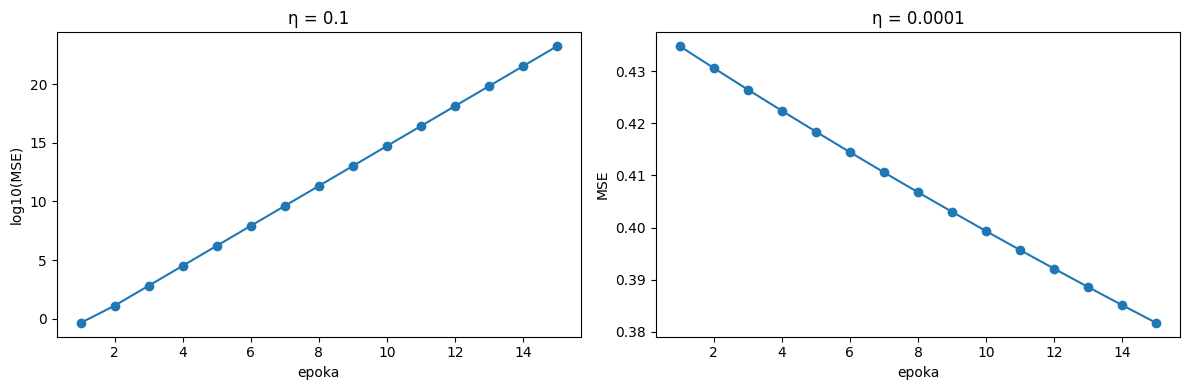

η = 0.1:    MSE w epokach 1, 2, 3: [  0.43  12.99 648.81]  ... w 15.: 1.7e+23
η = 0.0001: MSE w 1. i 15. epoce:  0.435 0.382
trafność:  η = 0.1: 0.5   η = 0.0001: 0.5


In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))

ada1 = AdalineGD(eta=0.1, n_iter=15).fit(X, y)
axs[0].plot(range(1, 16), np.log10(ada1.losses_), marker="o")
axs[0].set_xlabel("epoka"); axs[0].set_ylabel("log10(MSE)"); axs[0].set_title("η = 0.1")

ada2 = AdalineGD(eta=0.0001, n_iter=15).fit(X, y)
axs[1].plot(range(1, 16), ada2.losses_, marker="o")
axs[1].set_xlabel("epoka"); axs[1].set_ylabel("MSE"); axs[1].set_title("η = 0.0001")

plt.tight_layout(); plt.show()
print("η = 0.1:    MSE w epokach 1, 2, 3:", np.round(ada1.losses_[:3], 2), " ... w 15.:", f"{ada1.losses_[-1]:.1e}")
print("η = 0.0001: MSE w 1. i 15. epoce: ", round(ada2.losses_[0], 3), round(ada2.losses_[-1], 3))
print("trafność:  η = 0.1:", (ada1.predict(X) == y).mean(), "  η = 0.0001:", (ada2.predict(X) == y).mean())

Uwaga: lewy wykres ma oś pionową w skali logarytmicznej ($\log_{10}$). Wartość 20 oznacza stratę rzędu $10^{20}$.

**Pytanie 4.** Co się stało w obu przypadkach? Który przypadek z kartki 1 ($\eta = 0.25$, $1$, $1.1$) przypomina każdy z wykresów? Dlaczego oba modele mają trafność tylko 50%?

✍️ **Twoja odpowiedź:** Przy η = 0.1 strata rośnie z epoki na epokę (0.43, 12.99, 648.81, ..., 1.7·10²³ w 15. epoce), więc algorytm jest rozbieżny: kolejne kroki przeskakują minimum na drugą stronę i za każdym razem trafiają coraz dalej. To przypomina η = 1.1 z kartki 1 (|c| > 1, waga ucieka). Przy η = 0.0001 strata maleje, ale tak wolno (0.435 → 0.382 przez 15 epok), że model prawie się nie nauczył. To przypomina bardzo małe η na kartce 1, gdzie c jest bliskie 1 i waga ledwo się przesuwa (w kierunku 3). Oba modele mają trafność 50%, bo w obu przypadkach przewidują praktycznie jedną klasę dla wszystkich punktów: przy η = 0.1 wagi są gigantyczne i bezsensowne, a przy η = 0.0001 wagi są jeszcze za małe, żeby z przekroczyło próg 0.5 dla klasy 1.

### Zadanie 3: granica stabilności

Ucz Adaline przez **100 epok** dla $\eta \in \{0.001,\ 0.01,\ 0.02,\ 0.022,\ 0.024,\ 0.025,\ 0.026,\ 0.03\}$. Dla każdego $\eta$ wypisz MSE w pierwszej i ostatniej epoce oraz trafność. Znajdź największe $\eta$, przy którym strata jeszcze **maleje**.

(Przy dużych $\eta$ liczby mogą wyjść poza zakres `float` i NumPy wypisze ostrzeżenie o przepełnieniu — linijka `np.errstate` je wycisza.)

In [ ]:
with np.errstate(over="ignore", invalid="ignore"):
    for eta in [0.001, 0.01, 0.02, 0.022, 0.024, 0.025, 0.026, 0.03]:
        a = AdalineGD(eta=eta, n_iter=100).fit(X, y)
        print(f"η = {eta:<6} MSE 1. epoka: {a.losses_[0]:10.4g}   MSE 100. epoka: {a.losses_[-1]:10.4g}   trafność: {(a.predict(X) == y).mean():.0%}")

η = 0.001  MSE 1. epoka:     0.4348   MSE 100. epoka:     0.1202   trafność: 100%
η = 0.01   MSE 1. epoka:     0.4348   MSE 100. epoka:    0.01443   trafność: 100%
η = 0.02   MSE 1. epoka:     0.4348   MSE 100. epoka:    0.01243   trafność: 100%
η = 0.022  MSE 1. epoka:     0.4348   MSE 100. epoka:    0.01242   trafność: 100%
η = 0.024  MSE 1. epoka:     0.4348   MSE 100. epoka:    0.01241   trafność: 100%
η = 0.025  MSE 1. epoka:     0.4348   MSE 100. epoka:      32.36   trafność: 50%
η = 0.026  MSE 1. epoka:     0.4348   MSE 100. epoka:  1.124e+08   trafność: 50%
η = 0.03   MSE 1. epoka:     0.4348   MSE 100. epoka:  1.399e+30   trafność: 50%


**Pytanie 5.** Gdzie leży granica stabilności dla tych danych? Porównaj z granicą $\eta < 1$ z punktu 1. Dlaczego tutaj jest dużo mniejsza?

✍️ **Twoja odpowiedź:** Granica stabilności leży między η = 0.024 a η = 0.025. Dla η ≤ 0.024 MSE maleje do ok. 0.0124 i trafność jest 100%, a dla η = 0.025 strata rośnie (32 po 100 epokach, a w mapie 4·10²⁰ po 1000 epokach), dla 0.026 i 0.03 rośnie jeszcze szybciej (10⁸, 10³⁰) i trafność spada do 50%. Na kartce 1 granica to η < 1, bo L = (w − 3)² ma drugą pochodną 2 i warunek wychodzi η < 2/2. Tutaj krzywizna funkcji straty zależy od wartości cech: gradient jest mnożony przez x (kilka cm), więc największa krzywizna L jest rzędu 80 (η_max ≈ 2/80 ≈ 0.025), dużo większa niż 2. Im większa krzywizna, tym mniejsze η, żeby krok nie przeskakiwał dna doliny. Dlatego granica jest ok. 40 razy mniejsza.

## 5. Mapa $\eta$ × epoki

Czy za małe $\eta$ da się nadrobić większą liczbą epok? A za duże?

### Zadanie 4
Dla $\eta \in \{0.001,\ 0.005,\ 0.01,\ 0.02,\ 0.025\}$ i liczby epok $\in \{15,\ 100,\ 1000\}$ naucz Adaline i zapisz MSE w ostatniej epoce oraz trafność. Wypisz wyniki jako tabelę: wiersze to $\eta$, kolumny to liczba epok.

**Przewiduję:** czy $\eta = 0.001$ po 1000 epokach dogoni $\eta = 0.01$ po 100 epokach?

✍️ **Moje przewidywanie (zapisz przed uruchomieniem):** Przewiduję, że tak, mniej więcej dogoni: η jest 10 razy mniejsze, więc potrzeba ok. 10 razy więcej epok, czyli 1000 epok przy η = 0.001 powinno dać podobną stratę jak 100 epok przy η = 0.01.

In [ ]:
etas = [0.001, 0.005, 0.01, 0.02, 0.025]
epoki = [15, 100, 1000]

print("η        " + "".join(f"{n:>22} epok" for n in epoki))
with np.errstate(over="ignore", invalid="ignore"):
    for eta in etas:
        wiersz = f"{eta:<8} "
        for n in epoki:
            a = AdalineGD(eta=eta, n_iter=n).fit(X, y)
            mse = a.losses_[-1]
            traf = (a.predict(X) == y).mean()
            wiersz += f"{mse:>14.3g} / {traf:.0%}".rjust(27)
        print(wiersz)

η                            15 epok                   100 epok                  1000 epok
0.001                    0.193 / 74%                0.12 / 100%              0.0144 / 100%
0.005                   0.135 / 100%               0.031 / 100%              0.0124 / 100%
0.01                    0.102 / 100%              0.0144 / 100%              0.0124 / 100%
0.02                   0.0596 / 100%              0.0124 / 100%              0.0123 / 100%
0.025                    0.553 / 50%                 32.4 / 50%              4.2e+20 / 50%


Zobaczmy to samo na wykresie: krzywe strat dla wszystkich $\eta$ przez 1000 epok (oś pozioma w skali logarytmicznej, żeby było widać i początek, i koniec).

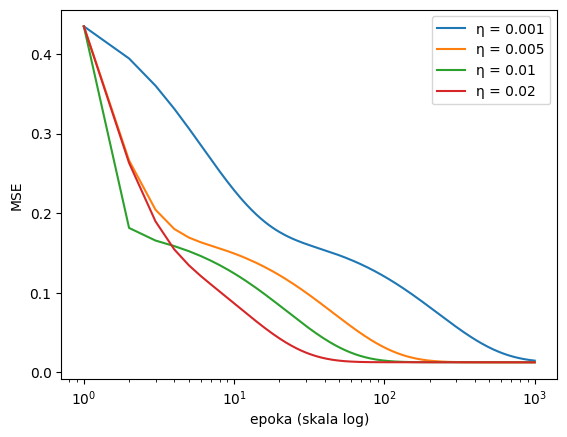

In [ ]:
with np.errstate(over="ignore", invalid="ignore"):
    for eta in [0.001, 0.005, 0.01, 0.02]:
        a = AdalineGD(eta=eta, n_iter=1000).fit(X, y)
        plt.plot(range(1, 1001), a.losses_, label=f"η = {eta}")
plt.xscale("log"); plt.xlabel("epoka (skala log)"); plt.ylabel("MSE")
plt.legend(); plt.show()

**Pytanie 6.** Odpowiedz na podstawie tabeli i wykresu:
1. Ile epok potrzebuje $\eta = 0.001$, żeby dojść tam, gdzie $\eta = 0.01$ dochodzi po 100 epokach? Co z tego wynika?
2. Czy strata może spaść do zera? Co się dzieje, gdy dojdzie do „dna”?
3. Czy więcej epok pomaga przy $\eta = 0.025$?
4. Trafność 100% pojawia się dużo wcześniej niż „dno” straty. Co to znaczy?

✍️ **Twoja odpowiedź:** 1. Tak, mniej więcej dogoni: η = 0.001 po 1000 epokach ma MSE 0.0144, tyle samo co η = 0.01 po 100 epokach (0.0144). Dziesięć razy mniejsze η wymaga więc ok. 10 razy więcej epok. Za małe η można nadrobić większą liczbą epok, ale kosztem czasu uczenia.
2. Nie, strata nie spada do zera. Dochodzi do dna na poziomie ok. 0.0123–0.0124 (η = 0.005 po 1000 epokach ma 0.0124, η = 0.02 ma 0.0123). Etykiety 0/1 nie da się dokładnie odtworzyć funkcją liniową z = w·x + b, więc minimum MSE jest większe od zera. Gdy strata dojdzie do dna, gradient jest bliski zera, wagi prawie przestają się zmieniać i krzywa na wykresie jest płaska.
3. Nie. Dla η = 0.025 jest odwrotnie: MSE rośnie z 0.553 (15 epok) przez 32.4 (100 epok) do 4.2·10²⁰ (1000 epok), a trafność jest 50%. Za duże η jest rozbieżne i więcej epok tylko pogarsza sytuację.
4. Trafność wymaga tylko, żeby z było po dobrej stronie progu 0.5 dla każdego punktu, a strata mierzy, jak blisko 0 lub 1 jest z. Można więc mieć 100% trafności, gdy z jest jeszcze daleko od etykiet i strata jest duża (np. η = 0.001 po 100 epokach: 100%, ale MSE 0.12 wobec 0.0123 na dnie). Trafność 100% nie oznacza, że model jest już nauczony do końca.

## 6. Granica decyzyjna w czasie

Przy $\eta = 0.01$ trafność 100% pojawia się już po kilku epokach. Czy wtedy uczenie się kończy?

Granica decyzyjna Adaline to prosta $z = 0.5$, czyli $w_1 x_1 + w_2 x_2 + b = 0.5$, więc

$$x_2 = \frac{0.5 - b - w_1 x_1}{w_2}.$$

Dla porównania mamy też perceptron z poprzednich zajęć (kod poniżej jest gotowy, uruchom go).

In [ ]:
class Perceptron:
    # Perceptron z poprzednich zajęć (etykiety 0/1, granica z = 0)
    def __init__(self, eta=0.1, n_iter=10, random_state=1):
        self.eta, self.n_iter, self.random_state = eta, n_iter, random_state

    def fit(self, X, y):
        rgen = np.random.RandomState(self.random_state)
        self.w_ = rgen.normal(loc=0.0, scale=0.01, size=X.shape[1])
        self.b_ = 0.0
        for _ in range(self.n_iter):
            for xi, target in zip(X, y):
                update = self.eta * (target - self.predict(xi))
                self.w_ += update * xi
                self.b_ += update
        return self

    def predict(self, X):
        return np.where(np.dot(X, self.w_) + self.b_ >= 0.0, 1, 0)

ppn = Perceptron(eta=0.1, n_iter=10).fit(X, y)
print("perceptron: w =", ppn.w_, " b =", ppn.b_, " trafność:", (ppn.predict(X) == y).mean())

perceptron: w = [-0.3538  0.9139]  b = -0.2  trafność: 1.0


### Zadanie 5
Narysuj na jednym wykresie punkty Iris oraz granice decyzyjne Adaline ($\eta = 0.01$) po $1, 5, 20, 100$ i $1000$ epokach. Dla każdej liczby epok wypisz też wagi, bias i trafność. Dorysuj granicę perceptronu (linia przerywana; dla perceptronu granica to $z = 0$, czyli $x_2 = -(b + w_1 x_1)/w_2$).

    1 epok: w = [0.0678 0.0324], b = 0.0086, trafność = 95%
    5 epok: w = [0.0658 0.0681], b = 0.0058, trafność = 100%
   20 epok: w = [0.0202 0.1545], b = -0.0098, trafność = 100%
  100 epok: w = [-0.0754  0.3356], b = -0.0411, trafność = 100%
 1000 epok: w = [-0.0994  0.3735], b = -0.0262, trafność = 100%


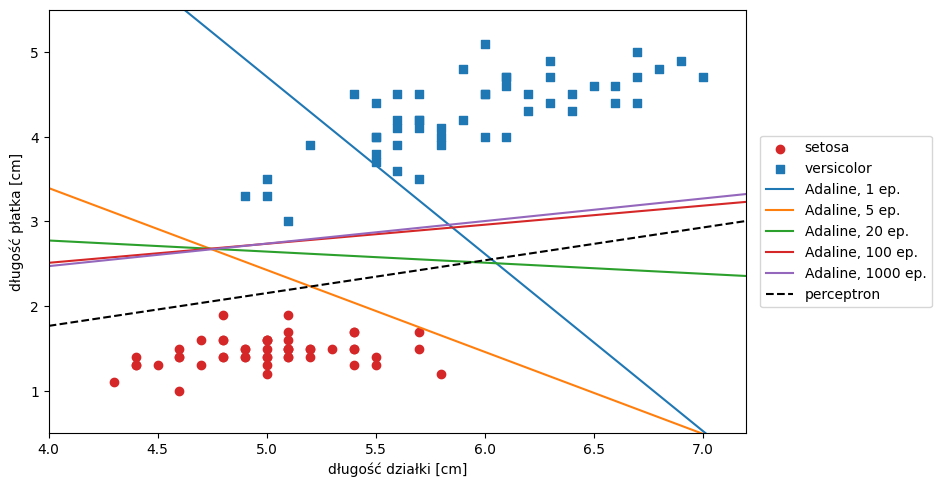

In [ ]:
x1 = np.linspace(4.0, 7.2, 2)
plt.figure(figsize=(9, 5.5))
plt.scatter(X[y == 0, 0], X[y == 0, 1], c="tab:red", marker="o", label="setosa")
plt.scatter(X[y == 1, 0], X[y == 1, 1], c="tab:blue", marker="s", label="versicolor")

for n in [1, 5, 20, 100, 1000]:
    a = AdalineGD(eta=0.01, n_iter=n).fit(X, y)
    print(f"{n:>5} epok: w = {a.w_}, b = {a.b_:.4f}, trafność = {(a.predict(X) == y).mean():.0%}")
    x2 = (0.5 - a.b_ - a.w_[0] * x1) / a.w_[1]
    plt.plot(x1, x2, label=f"Adaline, {n} ep.")

x2 = -(ppn.b_ + ppn.w_[0] * x1) / ppn.w_[1]
plt.plot(x1, x2, "k--", label="perceptron")

plt.xlim(4.0, 7.2); plt.ylim(0.5, 5.5)
plt.xlabel("długość działki [cm]"); plt.ylabel("długość płatka [cm]")
plt.legend(loc="center left", bbox_to_anchor=(1.01, 0.5)); plt.show()

**Pytanie 7.** Od której epoki trafność wynosi 100%? Co dzieje się z prostą później i dlaczego? Czym różni się położenie końcowej granicy Adaline od granicy perceptronu i skąd ta różnica?

✍️ **Twoja odpowiedź:** Dla η = 0.01 trafność po 1 epoce to 95%, a 100% jest od 5. epoki. Mimo to prosta dalej się przesuwa i obraca: wagi zmieniają się z [0.066, 0.068] (5 ep.) przez [0.020, 0.155] (20 ep.) i [−0.075, 0.336] (100 ep.) do [−0.099, 0.374] (1000 ep.), a później prawie stoi. Dzieje się tak, bo Adaline minimalizuje MSE, a nie liczbę pomyłek, więc dopóki strata nie jest na dnie, gradient jest niezerowy i wagi się poprawiają, nawet gdy wszystkie punkty są już dobrze sklasyfikowane. Perceptron kończy zmiany w chwili, gdy przestaje się mylić, więc jego granica zostaje tam, gdzie akurat była (zależy od danych, kolejności i wag startowych) i może leżeć blisko jednej z klas. Końcowa granica Adaline jest wyznaczona przez minimum straty, które uwzględnia wszystkie punkty naraz, więc nie zależy od kolejności i leży między klasami, a nie tam, gdzie algorytm przypadkiem przestał się mylić.

## 7. Podsumowanie

Odpowiedz krótko własnymi słowami (kliknij dwukrotnie, żeby edytować):

1. Czym różni się błąd w Adaline od błędu w perceptronie?

   **Odp.:** W perceptronie błąd to $y - \hat{y}$, gdzie $\hat y$ jest po funkcji skokowej, więc może być tylko $0, \pm 1$ i mówi tylko, czy się pomylił. W Adaline błąd to $y - z$, gdzie $z$ jest liniowe, więc to dowolna liczba, która mówi, jak bardzo model się myli.

2. Co to jest funkcja straty i co znaczy „uczenie” w Adaline?

   **Odp.:** Funkcja straty (MSE) to jedna liczba mówiąca, jak źle model radzi sobie na całym zbiorze. Uczenie to szukanie wag i biasu, dla których strata jest jak najmniejsza, spadkiem gradientu: w każdej epoce robimy krok w stronę przeciwną do gradientu.

3. Dlaczego w Adaline $\eta$ ma duże znaczenie, a w perceptronie (przy starcie od zera) nie miało?

   **Odp.:** W perceptronie przy zerowych wagach liczy się tylko znak $z$, a $\eta$ skaluje tylko wagi i nie zmienia znaku, więc granica jest ta sama. W Adaline poprawka zależy od wartości błędu $y - z$ i od $\eta$, więc $\eta$ decyduje o długości kroku: za duże rozbija uczenie (rozbieżność), za małe sprawia, że uczenie jest bardzo wolne.

4. Czy za małe $\eta$ można nadrobić liczbą epok? A za duże?

   **Odp.:** Za małe tak: 10 razy mniejsze $\eta$ potrzebuje mniej więcej 10 razy więcej epok, ale to kosztuje czas. Za duże nie: powyżej granicy stabilności (tu ok. 0.025, w 1D $\eta \ge 1$) strata rośnie i więcej epok tylko pogarsza wynik.

5. Dlaczego granica decyzyjna Adaline przesuwa się dalej, chociaż trafność jest już 100%?

   **Odp.:** Bo Adaline minimalizuje MSE, a nie liczbę błędów. Trafność 100% wymaga tylko, żeby każdy punkt był po dobrej stronie progu 0.5, a strata mierzy odległość $z$ od 0 lub 1. Dopóki strata nie jest na dnie, gradient jest niezerowy i wagi się zmieniają, więc prosta jeszcze się przesuwa.


---
## Zadanie dodatkowe (na ocenę 4/5)

Wróć do dwóch problemów, na których poległ perceptron (bez standaryzacji):

1. **versicolor vs virginica** (kwiaty 50–149, cechy 0 i 2, klasa 1 = virginica). Naucz Adaline dla $\eta \in \{0.001,\ 0.01,\ 0.02\}$ przez 1000 epok. Narysuj straty i regiony decyzyjne dla najlepszego $\eta$, policz trafność. Czy uczenie się stabilizuje? Porównaj z zachowaniem perceptronu. Czy granica stabilności jest taka sama jak dla setosa/versicolor?
2. **XOR** (4 punkty, etykiety $0, 1, 1, 0$). Naucz Adaline ($\eta = 0.1$, 500 epok, `w_init="zeros"`). Wypisz końcowe wagi, bias i $z$ dla czterech punktów. Co „wymyślił” model i dlaczego?

**Odpowiedzi:**

1. *versicolor vs virginica.* Wyniki po 1000 epokach: η = 0.001 daje MSE 0.153 i trafność 95%, η = 0.01 daje MSE 0.078 i trafność 93%, a η = 0.02 jest rozbieżne (MSE = inf, trafność 50%). Najlepsze (najmniejsza strata) jest η = 0.01, i dla niego narysowałem straty i regiony decyzyjne. Uczenie się stabilizuje: strata dochodzi do dna (ok. 0.078) i wagi przestają się zmieniać. Perceptron tego nie robił: ciągle się mylił, wagi dryfowały i nie było zbieżności. Trafność Adaline nie jest 100%, bo klasy nie są liniowo rozdzielne, ale wynik jest stabilny i nie zależy od momentu zatrzymania. Zauważ, że η = 0.001 ma lepszą trafność (95%) niż η = 0.01 (93%), mimo większej straty, bo strata i trafność to nie to samo. Granica stabilności jest inna niż dla setosa/versicolor: tam było stabilne η ≤ 0.024, a tu już η = 0.02 jest rozbieżne, więc granica leży między 0.01 a 0.02. Cechy virginica mają większe wartości (większa długość płatka), więc krzywizna funkcji straty jest większa, a przez to dopuszczalne η mniejsze.
2. *XOR.* Końcowe wagi to w = [0, 0] i b = 0.5, a z = 0.5 dla wszystkich czterech punktów (MSE = 0.25). Model „wymyślił” funkcję stałą równą średniej etykiet (0.5), bo funkcją liniową nie da się dopasować XOR (punkty nie są liniowo separowalne, a najlepsze dopasowanie najmniejszych kwadratów to stała). Skoro z leży dokładnie na progu 0.5, klasy po progu zależą od szumu zmiennoprzecinkowego (w tym uruchomieniu wyszło [0, 0, 0, 1], trafność 25%) i nie mają sensu.


η = 0.001  MSE 1. ep.:    0.4321  MSE 1000. ep.:    0.1532  trafność: 95%
η = 0.01   MSE 1. ep.:    0.4321  MSE 1000. ep.:   0.07789  trafność: 93%
η = 0.02   MSE 1. ep.:    0.4321  MSE 1000. ep.:       inf  trafność: 50%
najlepsze η: 0.01  w = [-0.4517  0.7324]  b = -0.2589


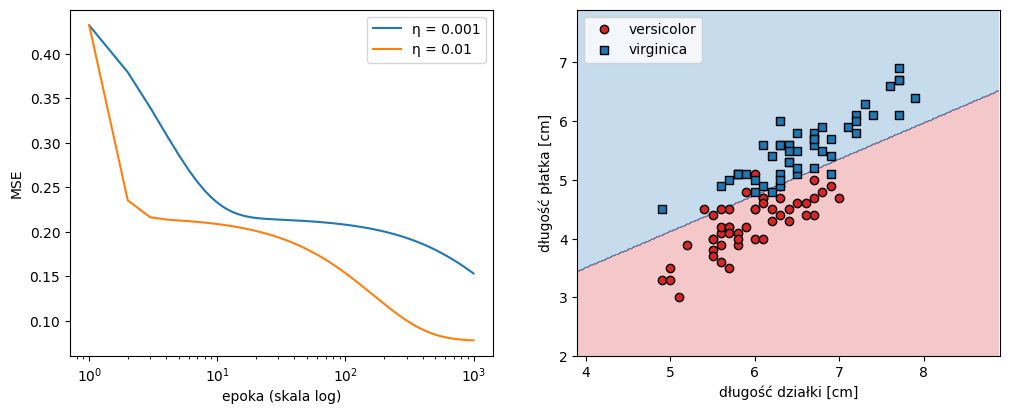

η = 0.02: MSE w 100. epoce = 1.746e+40
η = 0.025: MSE w 100. epoce = 3.192e+69
η = 0.03: MSE w 100. epoce = 1.98e+91
XOR: w = [0. 0.]  b = 0.5
z dla 4 punktów: [0.5 0.5 0.5 0.5]  MSE: 0.25
predykcje: [0 0 0 1]  trafność: 0.25


In [ ]:
X2 = iris.data[50:][:, [0, 2]]
y2 = (iris.target[50:] == 2).astype(int)

modele = {}
with np.errstate(over="ignore", invalid="ignore"):
    for eta in [0.001, 0.01, 0.02]:
        a = AdalineGD(eta=eta, n_iter=1000).fit(X2, y2)
        modele[eta] = a
        print(f"η = {eta:<6} MSE 1. ep.: {a.losses_[0]:9.4g}  MSE 1000. ep.: {a.losses_[-1]:9.4g}  trafność: {(a.predict(X2) == y2).mean():.0%}")

najlepsze = min((e for e in modele if np.isfinite(modele[e].losses_[-1])), key=lambda e: modele[e].losses_[-1])
best = modele[najlepsze]
print("najlepsze η:", najlepsze, " w =", best.w_, " b =", round(best.b_, 4))

fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))
for eta, a in modele.items():
    if np.isfinite(a.losses_[-1]) and a.losses_[-1] < 10:
        axs[0].plot(range(1, 1001), a.losses_, label=f"η = {eta}")
axs[0].set_xscale("log"); axs[0].set_xlabel("epoka (skala log)"); axs[0].set_ylabel("MSE"); axs[0].legend()
plot_decision_regions(X2, y2, best, ax=axs[1], etykiety=("versicolor", "virginica"))
axs[1].set_xlabel("długość działki [cm]"); axs[1].set_ylabel("długość płatka [cm]")
plt.show()

with np.errstate(over="ignore", invalid="ignore"):
    for eta in [0.02, 0.025, 0.03]:
        a = AdalineGD(eta=eta, n_iter=100).fit(X2, y2)
        print(f"η = {eta}: MSE w 100. epoce = {a.losses_[-1]:.4g}")

X_xor = np.array([[0, 0], [1, 0], [0, 1], [1, 1]], dtype=float)
y_xor = np.array([0, 1, 1, 0])
ada_xor = AdalineGD(eta=0.1, n_iter=500, w_init="zeros").fit(X_xor, y_xor)
print("XOR: w =", ada_xor.w_, " b =", round(ada_xor.b_, 4))
print("z dla 4 punktów:", ada_xor.net_input(X_xor), " MSE:", round(ada_xor.losses_[-1], 4))
print("predykcje:", ada_xor.predict(X_xor), " trafność:", (ada_xor.predict(X_xor) == y_xor).mean())
